In [2]:

import numpy as np
import pandas as pd
import os
import rioxarray as rxr
from osgeo import gdal
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline, make_pipeline
import geopandas as gpd
import rasterio
from shapely.geometry import box
from shapely.geometry import Point
from rasterio.sample import sample_gen
import xgboost as xgb

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from skopt import BayesSearchCV
from skopt.space import Integer, Real

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [ ]:
raster_path = 'G:\\ICESat-2\\Region4_map\\Region4b_map\\A2019\\Region4b_2019_FB6_new2.tif'
raster_path2 = 'G:\\ICESat-2\\Region4_map\\Region4b_map\\A2019\\Region4b_2019_FB6_new7.tif'
output_path = 'G:\\ICESat-2\\Region4_map\\Region4b_map\\A2019\\Region4b_2019_FB6_replaced.tif'

# 打开两个影像
with rasterio.open(raster_path) as src1, rasterio.open(raster_path2) as src2:
    data1 = src1.read()  # shape: (bands, height, width)
    band7_from_src2 = src2.read(7)  # 第7个波段（注意：波段索引从1开始）

    # 替换 data1 的第7个波段（Python索引从0开始）
    data1[7] = band7_from_src2

    # 保存新影像
    profile = src1.profile
    with rasterio.open(output_path, 'w', **profile) as dst:
        dst.write(data1)

In [ ]:
# raster_path = 'G:\ICESat-2\Region4_map\Region4b_map\A2021\Region4b_2021_FB6_new2.tif'
# raster_path2 = 'G:\ICESat-2\Region4_map\Region4b_map\A2021\Region4b_2021_FB6_new7.tif'
# output_raster_path2 = 'G:\ICESat-2\Region4_map\Region4b_map\A2021\Region4b_2021_FB6_new7_.tif'

year_list = [2019, 2020, 2021, 2022, 2023, 2024]
for i in range(len(year_list)):
    
    year = year_list[i]
    
    raster_path = f'G:\ICESat-2\Region4_map\Region4b_map\A{year}\Region4b_{year}_FB6_new2.tif'
    raster_path2 = f'G:\ICESat-2\Region4_map\Region4b_map\A{year}\Region4b_{year}_FB6_new7.tif'
    output_raster_path2 = f'G:\ICESat-2\Region4_map\Region4b_map\A{year}\Region4b_{year}_FB6_new7_.tif'
    
    with rasterio.open(raster_path) as src1, rasterio.open(raster_path2) as src2:
        
        data1 = src2.read() 
        print(data1.shape)
        band6_src1 = src1.read(5)
        
        data1[6] = band6_src1
        profile = src2.profile
        with rasterio.open(output_raster_path2, 'w', **profile) as dst:
            
            dst.write(data1)

(7, 2616, 2897)
(7, 2616, 2897)
(7, 2616, 2897)
(7, 2616, 2897)
(7, 2616, 2897)
(7, 2616, 2897)


In [25]:
import rasterio
from rasterio.mask import mask
import geopandas as gpd
import matplotlib.pyplot as plt

year_list = [2019, 2020, 2021, 2022, 2023, 2024]
# year_list = [2019]
for i in range(len(year_list)):

    raster_path = f'G:\ICESat-2\Region4_map\Severn_map\A{year_list[i]}\Severn_{year_list[i]}_FB6_new7.tif'
    shapefile_path = 'G:\ICESat-2\Region4_map\Parrett_map\Parrett_roi.shp'
    
    output_raster_path = f'G:\ICESat-2\Region4_map\Parrett_map\A{year_list[i]}\Parrett_{year_list[i]}_FB6_new7.tif'

    # 读取矢量文件
    shapefile = gpd.read_file(shapefile_path)

    # 矢量转为 GeoJSON 格式（只提取 geometry）
    shapes = shapefile.geometry.values

    # 打开raster
    with rasterio.open(raster_path) as src:
        # 使用矢量数据裁剪raster
        out_image, out_transform = mask(src, shapes, crop=True)
        out_meta = src.meta.copy()

    # 更新裁剪后的元数据
    out_meta.update({
        "driver": "GTiff",
        "height": out_image.shape[1],
        "width": out_image.shape[2],
        "transform": out_transform
    })

    #保存裁剪后的raster
    with rasterio.open(output_raster_path, "w", **out_meta) as dest:
        dest.write(out_image)

    print(f'Complete ! output to {output_raster_path}')



Complete ! output to G:\ICESat-2\Region4_map\Parrett_map\A2019\Parrett_2019_FB6_new7.tif
Complete ! output to G:\ICESat-2\Region4_map\Parrett_map\A2020\Parrett_2020_FB6_new7.tif
Complete ! output to G:\ICESat-2\Region4_map\Parrett_map\A2021\Parrett_2021_FB6_new7.tif
Complete ! output to G:\ICESat-2\Region4_map\Parrett_map\A2022\Parrett_2022_FB6_new7.tif
Complete ! output to G:\ICESat-2\Region4_map\Parrett_map\A2023\Parrett_2023_FB6_new7.tif
Complete ! output to G:\ICESat-2\Region4_map\Parrett_map\A2024\Parrett_2024_FB6_new7.tif


In [6]:
#point_path = 'G:\ICESat-2\Region4_map\Ribble1_map\Ribble_line_2_point.shp'
# point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Morecambe_map\Morecambe_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Ribble_map\Dee_line_2_points.shp'
#point_path = 'G:\ICESat-2\Region4_map\Solway_map\Solway_line_2_points.shp'
point_path = 'G:\ICESat-2\Region1_map\Thames1_map\Thames_2019_2_points.shp'
point_path = 'G:\ICESat-2\Region3_map\Region3b1_map\Holy_2021_line_2_points.shp'
point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_2021_line_2_points.shp'

points = gpd.read_file(point_path)
points['seq'] = range(0, len(points))
print(points.columns)

points['distance'] = points['seq'] * 30
# points = points[points['Ref'] != 6] 
points.loc[points['Ref'] == 6] = np.nan
points.loc[points['Re_DEM'] == 0] = np.nan

# points = points[points['Retri_dtm'] != 0] 

Index(['Id', 'ORIG_FID', 'Id_1', 'Retri_dtm', 'Ref', 'Retri_dtm2', 'Re_DEM',
       'geometry', 'seq'],
      dtype='object')


Index(['Id', 'ORIG_FID', 'Id_1', 'Retri_dtm', 'Ref', 'Retri_dtm2', 'Re_DEM',
       'geometry', 'seq'],
      dtype='object')


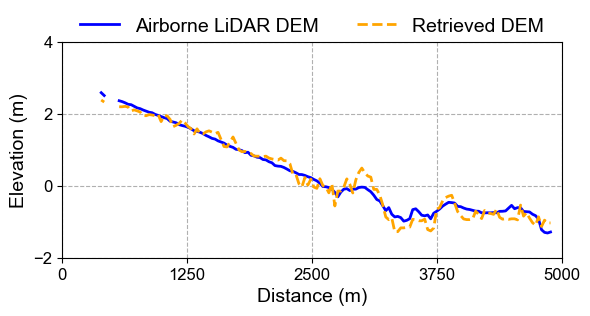

In [169]:
df = points
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'

point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_2021_line_2_points.shp'

points = gpd.read_file(point_path)
points['seq'] = range(0, len(points))
print(points.columns)

points['distance'] = points['seq'] * 30
# points = points[points['Ref'] != 6] 
points.loc[points['Ref'] == 6] = np.nan
points.loc[points['Re_DEM'] == 0] = np.nan


plt.figure(figsize=(6, 3))
plt.plot(df['distance'], df['Ref'], label='Airborne LiDAR DEM', color='blue',  linewidth=2)
# plt.plot(df['distance'], df['Retri_dtm2'], label='Retri_dtm', color='gray', linestyle='--',  linewidth=2)
plt.plot(df['distance'], df['Re_DEM'], label='Retrieved DEM', color='orange', linestyle='--',  linewidth=2)


plt.xlim(0,5000)
plt.xticks(np.arange(0, 5001, 1250))
plt.ylim(-2, 4)
plt.yticks(np.arange(-2, 5, 2))
plt.grid(axis='x', linestyle='--', alpha=1) 
plt.grid(axis='y', linestyle='--', alpha=1) 
plt.xticks( fontsize = 12)
plt.yticks( fontsize = 12)
plt.xlabel('Distance (m)', fontsize = 14)
plt.ylabel('Elevation (m)', fontsize = 14)
#plt.title('Elevation Comparison along Distance')
plt.legend(fontsize = 14)
plt.grid(True)
plt.tight_layout()

plt.legend(
    loc='lower center',      # 图例放在轴的下方（但我们用 bbox 调整到上方）
    bbox_to_anchor=(0.5, 0.95),  # 横向居中，纵向在坐标系上方
    ncol=2,                  # 控制图例横向排列个数（比如 3 个并排）
    fontsize=14,
    frameon=False            # 去掉边框（可选）
)

plt.show()

Index(['Id', 'ORIG_FID', 'Id_1', 'Ref', 'Retri_dtm', 'Re_DEM', 'geometry',
       'seq'],
      dtype='object')


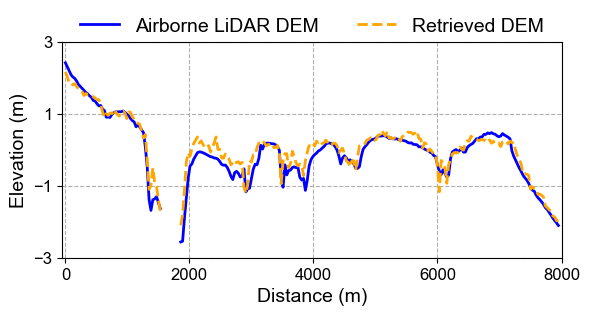

In [171]:
df = points
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'

point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_line_2_points.shp'

points = gpd.read_file(point_path)
points['seq'] = range(0, len(points))
print(points.columns)

points['distance'] = points['seq'] * 30
# points = points[points['Ref'] != 6] 
points.loc[points['Ref'] == 6] = np.nan
points.loc[points['Re_DEM'] == 0] = np.nan


plt.figure(figsize=(6, 3))
plt.plot(df['distance'], df['Ref'], label='Airborne LiDAR DEM', color='blue',  linewidth=2)
# plt.plot(df['distance'], df['Retri_dtm2'], label='Retri_dtm', color='gray', linestyle='--',  linewidth=2)
plt.plot(df['distance'], df['Re_DEM'], label='Retrieved DEM', color='orange', linestyle='--',  linewidth=2)


plt.xlim(-50,8000)
plt.xticks(np.arange(0, 8001, 2000),  fontsize = 12)
plt.ylim(-3, 3)
plt.yticks(np.arange(-3, 3.1, 2), fontsize = 12)
plt.grid(axis='x', linestyle='--', alpha=1) 
plt.grid(axis='y', linestyle='--', alpha=1) 

plt.xlabel('Distance (m)', fontsize = 14)
plt.ylabel('Elevation (m)', fontsize = 14)
#plt.title('Elevation Comparison along Distance')
#plt.legend(fontsize = 14)
plt.grid(True)
plt.tight_layout()
plt.legend(
    loc='lower center',      # 图例放在轴的下方（但我们用 bbox 调整到上方）
    bbox_to_anchor=(0.5, 0.95),  # 横向居中，纵向在坐标系上方
    ncol=2,                  # 控制图例横向排列个数（比如 3 个并排）
    fontsize=14,
    frameon=False            # 去掉边框（可选）
)
plt.show()

Index(['Id', 'ORIG_FID', 'Id_1', 'Retri_dtm', 'Ref', 'Re_DEM', 'geometry',
       'seq'],
      dtype='object')


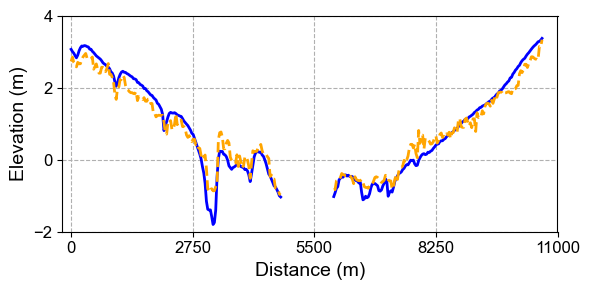

In [154]:
df = points
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'

point_path = 'G:\ICESat-2\Region4_map\Morecambe_map\Morecambe_line_2_points.shp'

points = gpd.read_file(point_path)
points['seq'] = range(0, len(points))
print(points.columns)

points['distance'] = points['seq'] * 30
# points = points[points['Ref'] != 6] 
points.loc[points['Ref'] == 6] = np.nan
points.loc[points['Re_DEM'] == 0] = np.nan


plt.figure(figsize=(6, 3))
plt.plot(df['distance'], df['Ref'], label='Airborne LiDAR DEM', color='blue',  linewidth=2)
# plt.plot(df['distance'], df['Retri_dtm2'], label='Retri_dtm', color='gray', linestyle='--',  linewidth=2)
plt.plot(df['distance'], df['Re_DEM'], label='Retrieved DEM', color='orange', linestyle='--',  linewidth=2)


plt.xlim(-200,11000)
plt.xticks(np.arange(0, 11001, 2750),  fontsize = 12)
plt.ylim(-2, 4)
plt.yticks(np.arange(-2, 4.1, 2), fontsize = 12)
plt.grid(axis='x', linestyle='--', alpha=1) 
plt.grid(axis='y', linestyle='--', alpha=1) 

plt.xlabel('Distance (m)', fontsize = 14)
plt.ylabel('Elevation (m)', fontsize = 14)
#plt.title('Elevation Comparison along Distance')
#plt.legend(fontsize = 14)
plt.grid(True)
plt.tight_layout()
plt.show()

Index(['Id', 'ORIG_FID', 'Id_1', 'Retri_dtm', 'Ref', 'Re_DEM', 'geometry',
       'seq'],
      dtype='object')


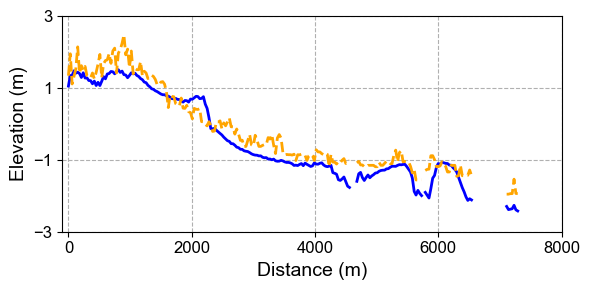

In [151]:
df = points
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'


#point_path = 'G:\ICESat-2\Region4_map\Ribble1_map\Ribble_line_2_point.shp'
# point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Morecambe_map\Morecambe_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Ribble_map\Dee_line_2_points.shp'
#point_path = 'G:\ICESat-2\Region4_map\Solway_map\Solway_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region1_map\Thames1_map\Thames_2019_2_points.shp'
# point_path = 'G:\ICESat-2\Region3_map\Region3b1_map\Holy_2021_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_2021_line_2_points.shp'

point_path = 'G:\ICESat-2\Region4_map\Solway_map\Solway_line_2_points.shp'

points = gpd.read_file(point_path)
points['seq'] = range(0, len(points))
print(points.columns)

points['distance'] = points['seq'] * 30
# points = points[points['Ref'] != 6] 
points.loc[points['Ref'] == 6] = np.nan
points.loc[points['Re_DEM'] == 0] = np.nan


plt.figure(figsize=(6, 3))
plt.plot(df['distance'], df['Ref'], label='Airborne LiDAR DEM', color='blue',  linewidth=2)
# plt.plot(df['distance'], df['Retri_dtm2'], label='Retri_dtm', color='gray', linestyle='--',  linewidth=2)
plt.plot(df['distance'], df['Retri_dtm'], label='Retrieved DEM', color='orange', linestyle='--',  linewidth=2)


plt.xlim(-100,8000)
plt.xticks(np.arange(0, 8001, 2000),  fontsize = 12)
plt.ylim(-3, 3)
plt.yticks(np.arange(-3, 3.1, 2), fontsize = 12)
plt.grid(axis='x', linestyle='--', alpha=1) 
plt.grid(axis='y', linestyle='--', alpha=1) 

plt.xlabel('Distance (m)', fontsize = 14)
plt.ylabel('Elevation (m)', fontsize = 14)
#plt.title('Elevation Comparison along Distance')
#plt.legend(fontsize = 14)
plt.grid(True)
plt.tight_layout()
plt.show()

Index(['OBJECTID', 'ORIG_FID', 'Id', 'Ref', 'Retri_dtm', 'Re_DEM', 'geometry',
       'seq'],
      dtype='object')


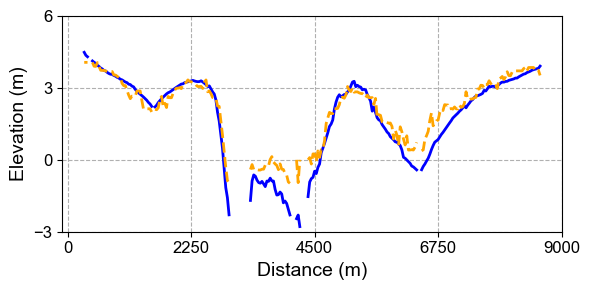

In [99]:
df = points
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'


#point_path = 'G:\ICESat-2\Region4_map\Ribble1_map\Ribble_line_2_point.shp'
# point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Morecambe_map\Morecambe_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Ribble_map\Dee_line_2_points.shp'
#point_path = 'G:\ICESat-2\Region4_map\Solway_map\Solway_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region1_map\Thames1_map\Thames_2019_2_points.shp'
# point_path = 'G:\ICESat-2\Region3_map\Region3b1_map\Holy_2021_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_2021_line_2_points.shp'

point_path = 'G:\ICESat-2\Region4_map\Ribble1_map\Ribble_line_2_point.shp'

points = gpd.read_file(point_path)
points['seq'] = range(0, len(points))
print(points.columns)

points['distance'] = points['seq'] * 30
# points = points[points['Ref'] != 6] 
points.loc[points['Ref'] == 6] = np.nan
points.loc[points['Re_DEM'] == 0] = np.nan


plt.figure(figsize=(6, 3))
plt.plot(df['distance'], df['Ref'], label='Airborne LiDAR DEM', color='blue',  linewidth=2)
# plt.plot(df['distance'], df['Retri_dtm2'], label='Retri_dtm', color='gray', linestyle='--',  linewidth=2)
plt.plot(df['distance'], df['Retri_dtm'], label='Retrieved DEM', color='orange', linestyle='--',  linewidth=2)


plt.xlim(-100,9000)
plt.xticks(np.arange(0, 9001, 2250),  fontsize = 12)
plt.ylim(-3, 6)
plt.yticks(np.arange(-3, 6.1, 3), fontsize = 12)
plt.grid(axis='x', linestyle='--', alpha=1) 
plt.grid(axis='y', linestyle='--', alpha=1) 

plt.xlabel('Distance (m)', fontsize = 14)
plt.ylabel('Elevation (m)', fontsize = 14)
#plt.title('Elevation Comparison along Distance')
#plt.legend(fontsize = 14)
plt.grid(True)
plt.tight_layout()
plt.show()

Index(['Id', 'ORIG_FID', 'Id_1', 'Ref', 'Retri_dtm', 'Re_DEM', 'geometry',
       'seq'],
      dtype='object')


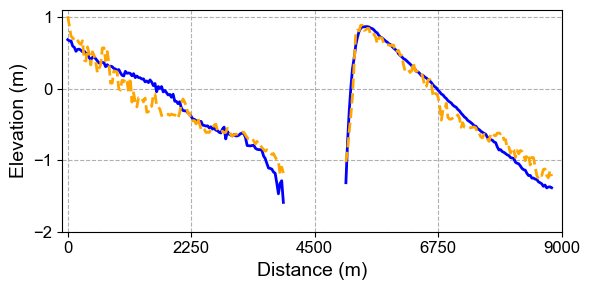

In [103]:
df = points
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'


#point_path = 'G:\ICESat-2\Region4_map\Ribble1_map\Ribble_line_2_point.shp'
# point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Morecambe_map\Morecambe_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Ribble_map\Dee_line_2_points.shp'
#point_path = 'G:\ICESat-2\Region4_map\Solway_map\Solway_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region1_map\Thames1_map\Thames_2019_2_points.shp'
# point_path = 'G:\ICESat-2\Region3_map\Region3b1_map\Holy_2021_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_2021_line_2_points.shp'

point_path = 'G:\ICESat-2\Region1_map\Thames1_map\Thames_2019_2_points.shp'

points = gpd.read_file(point_path)
points['seq'] = range(0, len(points))
print(points.columns)

points['distance'] = points['seq'] * 30
# points = points[points['Ref'] != 6] 
points.loc[points['Ref'] == 6] = np.nan
points.loc[points['Re_DEM'] == 0] = np.nan


plt.figure(figsize=(6, 3))
plt.plot(df['distance'], df['Ref'], label='Airborne LiDAR DEM', color='blue',  linewidth=2)
# plt.plot(df['distance'], df['Retri_dtm2'], label='Retri_dtm', color='gray', linestyle='--',  linewidth=2)
plt.plot(df['distance'], df['Re_DEM'], label='Retrieved DEM', color='orange', linestyle='--',  linewidth=2)


plt.xlim(-100,9000)
plt.xticks(np.arange(0, 9001, 2250),  fontsize = 12)
plt.ylim(-2, 1.1)
plt.yticks(np.arange(-2, 1.1, 1), fontsize = 12)
plt.grid(axis='x', linestyle='--', alpha=1) 
plt.grid(axis='y', linestyle='--', alpha=1) 

plt.xlabel('Distance (m)', fontsize = 14)
plt.ylabel('Elevation (m)', fontsize = 14)
#plt.title('Elevation Comparison along Distance')
#plt.legend(fontsize = 14)
plt.grid(True)
plt.tight_layout()
plt.show()

Index(['Id', 'ORIG_FID', 'Id_1', 'Retri_dtm', 'Ref', 'Re_DEM', 'DEM_join',
       'geometry', 'seq'],
      dtype='object')


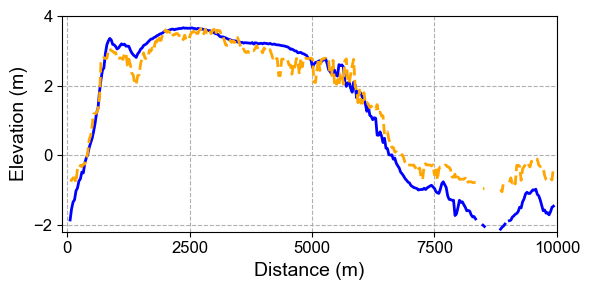

In [ ]:
df = points
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'


#point_path = 'G:\ICESat-2\Region4_map\Ribble1_map\Ribble_line_2_point.shp'
# point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Morecambe_map\Morecambe_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Ribble_map\Dee_line_2_points.shp'
#point_path = 'G:\ICESat-2\Region4_map\Solway_map\Solway_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region1_map\Thames1_map\Thames_2019_2_points.shp'
# point_path = 'G:\ICESat-2\Region3_map\Region3b1_map\Holy_2021_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_2021_line_2_points.shp'

point_path = 'G:\ICESat-2\Region4_map\Ribble_map\Dee_line_2_points.shp'

points = gpd.read_file(point_path)
points['seq'] = range(0, len(points))
print(points.columns)

points['distance'] = points['seq'] * 30
# points = points[points['Ref'] != 6] 
points.loc[points['Ref'] == 6] = np.nan
points.loc[points['Re_DEM'] == 0] = np.nan


plt.figure(figsize=(6, 3))
plt.plot(df['distance'], df['Ref'], label='Airborne LiDAR DEM', color='blue',  linewidth=2)
# plt.plot(df['distance'], df['Retri_dtm2'], label='Retri_dtm', color='gray', linestyle='--',  linewidth=2)
plt.plot(df['distance'], df['Retri_dtm'], label='Retrieved DEM', color='orange', linestyle='--',  linewidth=2)


plt.xlim(-100,10000)
plt.xticks(np.arange(0, 10001, 2500),  fontsize = 12)
plt.ylim(-2.2, 4)
plt.yticks(np.arange(-2, 4.1, 2), fontsize = 12)
plt.grid(axis='x', linestyle='--', alpha=1) 
plt.grid(axis='y', linestyle='--', alpha=1) 

plt.xlabel('Distance (m)', fontsize = 14)
plt.ylabel('Elevation (m)', fontsize = 14)
#plt.title('Elevation Comparison along Distance')
#plt.legend(fontsize = 14)
plt.grid(True)
plt.tight_layout()
plt.show()

Index(['Id', 'ORIG_FID', 'Id_1', 'Ref', 'Retri_dtm', 'Re_DEM', 'geometry',
       'seq'],
      dtype='object')


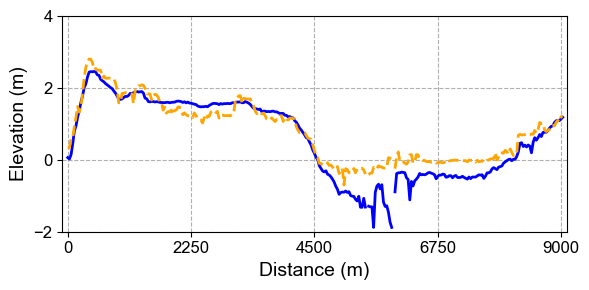

In [148]:
df = points
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'


#point_path = 'G:\ICESat-2\Region4_map\Ribble1_map\Ribble_line_2_point.shp'
# point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Morecambe_map\Morecambe_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Ribble_map\Dee_line_2_points.shp'
#point_path = 'G:\ICESat-2\Region4_map\Solway_map\Solway_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region1_map\Thames1_map\Thames_2019_2_points.shp'
# point_path = 'G:\ICESat-2\Region3_map\Region3b1_map\Holy_2021_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_2021_line_2_points.shp'

point_path = 'G:\ICESat-2\Region3_map\Region3b1_map\Holy_2021_line_2_points.shp'

points = gpd.read_file(point_path)
points['seq'] = range(0, len(points))
print(points.columns)

points['distance'] = points['seq'] * 30
# points = points[points['Ref'] != 6] 
points.loc[points['Ref'] == 6] = np.nan
points.loc[points['Re_DEM'] == 0] = np.nan
points.loc[points['Re_DEM'] == 0] = np.nan

plt.figure(figsize=(6, 3))
plt.plot(df['distance'], df['Ref'], label='Airborne LiDAR DEM', color='blue',  linewidth=2)
# plt.plot(df['distance'], df['Retri_dtm2'], label='Retri_dtm', color='gray', linestyle='--',  linewidth=2)
plt.plot(df['distance'], df['Re_DEM'], label='Retrieved DEM', color='orange', linestyle='--',  linewidth=2)


plt.xlim(-100,9100)
plt.xticks(np.arange(0, 9101, 2250),  fontsize = 12)
plt.ylim(-2.0, 4)
plt.yticks(np.arange(-2, 4.1, 2), fontsize = 12)
plt.grid(axis='x', linestyle='--', alpha=1) 
plt.grid(axis='y', linestyle='--', alpha=1) 

plt.xlabel('Distance (m)', fontsize = 14)
plt.ylabel('Elevation (m)', fontsize = 14)
#plt.title('Elevation Comparison along Distance')
#plt.legend(fontsize = 14)
plt.grid(True)
plt.tight_layout()
plt.show()

In [3]:
point_path = 'E:/UK_situ/Shp_data/profile/Profile_thames_2020.shp'
k = gpd.read_file(point_path)
k.columns

Index(['row', 'col', 'mean_val', 'pt_count', 'std', 'median_v', 'min', 'max',
       'UK_DEM_202', 'DEM_ref_co', 'distance', 'geometry'],
      dtype='object')

Index(['Id', 'ORIG_FID', 'Id_1', 'distance', 'Morecambe_', 'geometry'], dtype='object')


<Figure size 600x300 with 0 Axes>

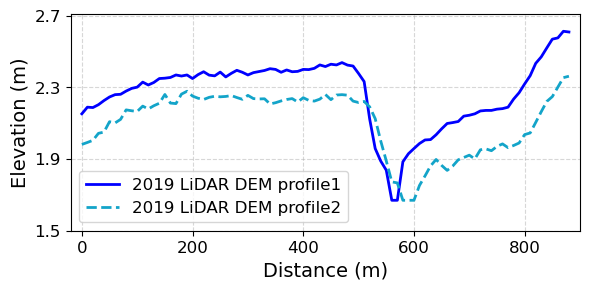

In [67]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
path = 'H:\DTM_ref\Morecambe\Morecambe_2019\Profile2.shp'
a = gpd.read_file(path)
path = 'H:\DTM_ref\Morecambe\Morecambe_2019\Profile1.shp'
b = gpd.read_file(path)
print(a.columns)
plt.figure(figsize=(6, 3))

# plt.plot(a[mask]['distance'], a[mask]['Morecambe_'])
# plt.scatter(a['distance'], a['Morecambe_'])
# plt.scatter(b['distance'], b['Morecambe_'])

# 对 a 排序
a_sorted = a.sort_values('distance')
b_sorted = b.sort_values('distance')

plt.figure(figsize=(6, 3))
plt.plot(a_sorted['distance']*10, a_sorted['Morecambe_'], label='2019 LiDAR DEM profile1', color='blue', linewidth=2)
plt.plot(b_sorted['distance']*10, b_sorted['Morecambe_'], label='2019 LiDAR DEM profile2', color="#13A4C9FF", linestyle='--', linewidth=2)

plt.xlim(-20,900)
plt.xticks(np.arange(0, 900, 200), fontsize=12)
plt.ylim(2,2.71)
plt.yticks(np.arange(1.5, 2.71, 0.4), fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlabel('Distance (m)', fontsize=14)
plt.ylabel('Elevation (m)', fontsize=14)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

In [56]:
a[10:20]

,Id,ORIG_FID,Id_1,distance,Morecambe_,geometry
10,0,0,1,60.0,1.959,POINT (505859.021 6000680.448)
11,0,0,1,61.0,1.987,POINT (505859.032 6000670.448)
12,0,0,1,62.0,2.007,POINT (505859.044 6000660.448)
13,0,0,1,63.0,2.009,POINT (505859.056 6000650.448)
14,0,0,1,64.0,2.036,POINT (505859.068 6000640.448)
15,0,0,1,65.0,2.069,POINT (505859.08 6000630.448)
16,0,0,1,66.0,2.099,POINT (505859.092 6000620.448)
17,0,0,1,67.0,2.104,POINT (505859.103 6000610.448)
18,0,0,1,68.0,2.110,POINT (505859.115 6000600.448)
19,0,0,1,69.0,2.140,POINT (505859.127 6000590.448)


Index(['row', 'col', 'mean_val', 'pt_count', 'std', 'median_v', 'min', 'max',
       'UK_DEM_202', 'DEM_ref_co', 'distance', 'geometry'],
      dtype='object')


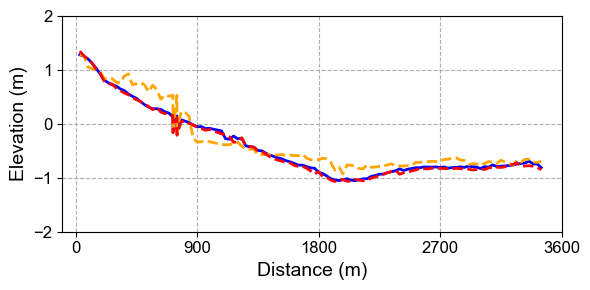

In [36]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'


#point_path = 'G:\ICESat-2\Region4_map\Ribble1_map\Ribble_line_2_point.shp'
# point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Morecambe_map\Morecambe_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Ribble_map\Dee_line_2_points.shp'
#point_path = 'G:\ICESat-2\Region4_map\Solway_map\Solway_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region1_map\Thames1_map\Thames_2019_2_points.shp'
# point_path = 'G:\ICESat-2\Region3_map\Region3b1_map\Holy_2021_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_2021_line_2_points.shp'

point_path = 'E:/UK_situ/Shp_data/profile/Profile_thames_2020.shp'

points = gpd.read_file(point_path)

# points['seq'] = range(0, len(points))
print(points.columns)

in_ref, re_dem, lidar_dem = 'median_v', 'UK_DEM_202', 'DEM_ref_co'

points['distance'] = points['distance'] * 30
points = points.sort_values(by='distance')  
df = points
# points = points[points['Ref'] != 6] 
points.loc[points[in_ref] == 6] = np.nan
points.loc[points[re_dem] == 0] = np.nan


plt.figure(figsize=(6, 3))
plt.plot(df['distance'], df[in_ref], label='Airborne LiDAR DEM', color='blue',  linewidth=2)
# plt.plot(df['distance'], df['Retri_dtm2'], label='Retri_dtm', color='gray', linestyle='--',  linewidth=2)
plt.plot(df['distance'], df[re_dem], label='Retrieved DEM', color='orange', linestyle='--',  linewidth=2)
plt.plot(df['distance'], df[lidar_dem], label='Retrieved DEM', color='red', linestyle='--',  linewidth=2)

plt.xlim(-100,3500)
plt.xticks(np.arange(0, 3601, 900),  fontsize = 12)
plt.ylim(-2,2)
plt.yticks(np.arange(-2, 2.1, 1), fontsize = 12)
plt.grid(axis='x', linestyle='--', alpha=1) 
plt.grid(axis='y', linestyle='--', alpha=1) 

plt.xlabel('Distance (m)', fontsize = 14)
plt.ylabel('Elevation (m)', fontsize = 14)
#plt.title('Elevation Comparison along Distance')
#plt.legend(fontsize = 14)
plt.grid(True)
plt.tight_layout()
plt.show()

Index(['row', 'col', 'mean_val', 'pt_count', 'std', 'median_v', 'min', 'max',
       'UK_DEM_202', 'DEM_ref_co', 'distance', 'geometry'],
      dtype='object')


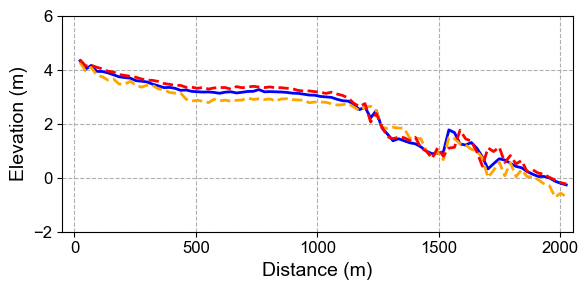

In [43]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'


#point_path = 'G:\ICESat-2\Region4_map\Ribble1_map\Ribble_line_2_point.shp'
# point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Morecambe_map\Morecambe_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region4_map\Ribble_map\Dee_line_2_points.shp'
#point_path = 'G:\ICESat-2\Region4_map\Solway_map\Solway_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region1_map\Thames1_map\Thames_2019_2_points.shp'
# point_path = 'G:\ICESat-2\Region3_map\Region3b1_map\Holy_2021_line_2_points.shp'
# point_path = 'G:\ICESat-2\Region2_map\wash_bay_map\wash_2021_line_2_points.shp'

point_path = 'E:/UK_situ/Shp_data/profile/Profile_ribble_2021.shp'

points = gpd.read_file(point_path)

# points['seq'] = range(0, len(points))
print(points.columns)

in_ref, re_dem, lidar_dem = 'median_v', 'UK_DEM_202', 'DEM_ref_co'

points['distance'] = points['distance'] * 23
points = points.sort_values(by='distance')  
df = points
# points = points[points['Ref'] != 6] 
points.loc[points[in_ref] == 6] = np.nan
points.loc[points[re_dem] == 0] = np.nan


plt.figure(figsize=(6, 3))
plt.plot(df['distance'], df[in_ref], label='Airborne LiDAR DEM', color='blue',  linewidth=2)
# plt.plot(df['distance'], df['Retri_dtm2'], label='Retri_dtm', color='gray', linestyle='--',  linewidth=2)
plt.plot(df['distance'], df[re_dem], label='Retrieved DEM', color='orange', linestyle='--',  linewidth=2)
plt.plot(df['distance'], df[lidar_dem], label='Retrieved DEM', color='red', linestyle='--',  linewidth=2)

plt.xlim(-50,2050)
plt.xticks(np.arange(0, 2001, 500),  fontsize = 12)
plt.ylim(-2,6)
plt.yticks(np.arange(-2, 6.1, 2), fontsize = 12)
plt.grid(axis='x', linestyle='--', alpha=1) 
plt.grid(axis='y', linestyle='--', alpha=1) 

plt.xlabel('Distance (m)', fontsize = 14)
plt.ylabel('Elevation (m)', fontsize = 14)
#plt.title('Elevation Comparison along Distance')
#plt.legend(fontsize = 14)
plt.grid(True)
plt.tight_layout()
plt.show()

Index(['row', 'col', 'mean_val', 'pt_count', 'std', 'median_v', 'min', 'max',
       'UK_DEM_201', 'DEM_ref_co', 'distance', 'geometry'],
      dtype='object')


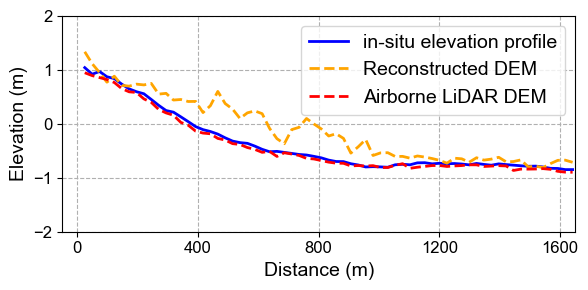

In [4]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'
point_path = 'E:/UK_situ/Shp_data/profile/Profile_wash_2019.shp'

points = gpd.read_file(point_path)

# points['seq'] = range(0, len(points))
print(points.columns)

in_ref, re_dem, lidar_dem = 'median_v', 'UK_DEM_201', 'DEM_ref_co'

points['distance'] = points['distance'] * 24.5
points = points.sort_values(by='distance')  
df = points
# points = points[points['Ref'] != 6] 
points.loc[points[in_ref] == 6] = np.nan
points.loc[points[re_dem] == 0] = np.nan


plt.figure(figsize=(6, 3))
plt.plot(df['distance'], df[in_ref], label='in-situ elevation profile', color='blue',  linewidth=2)
# plt.plot(df['distance'], df['Retri_dtm2'], label='Retri_dtm', color='gray', linestyle='--',  linewidth=2)
plt.plot(df['distance'], df[re_dem], label='Reconstructed DEM', color='orange', linestyle='--',  linewidth=2)
plt.plot(df['distance'], df[lidar_dem], label='Airborne LiDAR DEM', color='red', linestyle='--',  linewidth=2)

plt.xlim(-50,1650)
plt.xticks(np.arange(0, 1801, 400),  fontsize = 12)
plt.ylim(-2,2)
plt.yticks(np.arange(-2, 2.1, 1), fontsize = 12)
plt.grid(axis='x', linestyle='--', alpha=1) 
plt.grid(axis='y', linestyle='--', alpha=1) 

plt.xlabel('Distance (m)', fontsize = 14)
plt.ylabel('Elevation (m)', fontsize = 14)
#plt.title('Elevation Comparison along Distance')
plt.legend(fontsize = 14)
plt.grid(True)
plt.tight_layout()
plt.show()

Index(['row', 'col', 'mean_val', 'pt_count', 'std', 'median_v', 'min', 'max',
       'UK_DEM_202', 'DEM_ref_co', 'distance', 'geometry'],
      dtype='object')


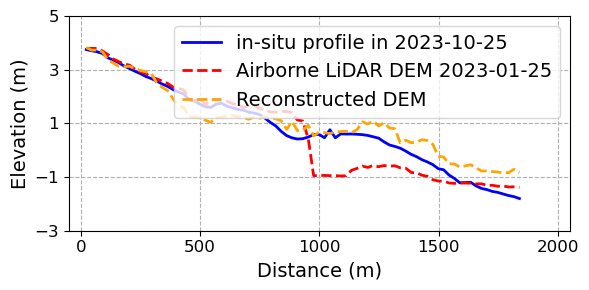

In [ ]:
point_path = 'E:/UK_situ/Shp_data/profile/Profile_Morecambe_2023.shp'

points = gpd.read_file(point_path)

# points['seq'] = range(0, len(points))
print(points.columns)

in_ref, re_dem, lidar_dem = 'median_v', 'UK_DEM_202', 'DEM_ref_co'

points['distance'] = points['distance'] * 22.7
points = points.sort_values(by='distance')  
df = points
points = points[points[re_dem] != 6] 
points.loc[points[in_ref] == 6] = np.nan
points.loc[points[re_dem] == 0] = np.nan


plt.figure(figsize=(6, 3))
plt.plot(df['distance'], df[in_ref], label='in-situ profile in', color='blue',  linewidth=2)
plt.plot(df['distance'], df[lidar_dem], label='Airborne LiDAR DEM 2023-01-25', color='red', linestyle='--',  linewidth=2)
# plt.plot(df['distance'], df['Retri_dtm2'], label='Retri_dtm', color='gray', linestyle='--',  linewidth=2)
plt.plot(df['distance'], df[re_dem], label='Reconstructed DEM', color='orange', linestyle='--',  linewidth=2)


plt.xlim(-50,2050)
plt.xticks(np.arange(0, 2001, 500),  fontsize = 12)
plt.ylim(-3,5)
plt.yticks(np.arange(-3, 5.1, 2), fontsize = 12)
plt.grid(axis='x', linestyle='--', alpha=1) 
plt.grid(axis='y', linestyle='--', alpha=1) 

plt.xlabel('Distance (m)', fontsize = 14)
plt.ylabel('Elevation (m)', fontsize = 14)
#plt.title('Elevation Comparison along Distance')
plt.legend(fontsize = 14)
plt.grid(True)
plt.tight_layout()
plt.show()

In [4]:
def save_img(output_filename, reference_filename, array):
    
    reference = gdal.Open(reference_filename)
    
    # 获取地理变换参数和坐标系
    geo_transform = reference.GetGeoTransform()
    projection = reference.GetProjection()

    # 获取矩阵尺寸
    rows, cols = array.shape

    # 创建新的 TIFF 数据集
    driver = gdal.GetDriverByName('GTiff')
    out_data = driver.Create(output_filename, cols, rows, 1, gdal.GDT_Float32)

    # 设置地理变换和坐标系
    out_data.SetGeoTransform(geo_transform)
    out_data.SetProjection(projection)
    

    # 写入数据
    out_data.GetRasterBand(1).WriteArray(array)

    # 保存并关闭文件
    out_data.FlushCache()
    out_data = None
    
def load_refer_icesat_point(FB_raster, icesat_csv_path, output_point, output_raw_point):
    
    df = pd.read_csv(icesat_csv_path)
    lon, lat = 'mean_lon', 'mean_lat'
    LULC_path = "E:/Downloads/tes/UK_LULC.tif"
    geometry = [Point(xy) for xy in zip(df[lon], df[lat])]
    gdf = gpd.GeoDataFrame(df, geometry=geometry)
    gdf.set_crs(epsg=4326, inplace=True)
    points = gdf
    
    with rasterio.open(FB_raster) as src:
        
        if points.crs != src.crs:
            points = points.to_crs(src.crs)
        coords = [(point.x, point.y) for point in points.geometry]
        values = list(src.sample(coords))
        
        band_count = src.count
        for band in range(band_count):
            points[f"b{band+1}_FB6"] = [v[band] for v in values]
            
    with rasterio.open(LULC_path) as src:

        if points.crs != src.crs:
            points = points.to_crs(src.crs)
        coords = [(point.x, point.y) for point in points.geometry]
        values = list(src.sample(coords))

        band_count = src.count
        points['LULC'] = [v[0] for v in values] 
     
    icesat_mask = (points['OH'] < 5) & (points['b5_FB6'] > 0) & ((points['LULC'] == 200) | (points['LULC'] == 80))
    data = points[icesat_mask]
    
    points.to_file(output_raw_point)
    data.to_file(output_point)
    
    return data

def optimize_random_forest(x_train, y_train,  n_iter=30, cv=3):

    # if feature_columns is None:
    #     raise ValueError("feature_columns must be provided.")

    classifier = RandomForestRegressor(random_state=42)

    search_space = {
        'n_estimators': Integer(50, 500),
        'max_depth': Integer(3, 20),
        'min_samples_split': Integer(2, 20),
        'min_samples_leaf': Integer(1, 20),
        'max_features': Real(0.1, 1.0)
    }

    opt = BayesSearchCV(
        estimator=classifier,
        search_spaces=search_space,
        n_iter=n_iter,
        cv=cv,
        scoring='neg_mean_squared_error',
        random_state=42,
        n_jobs=-1
    )

    opt.fit(x_train, y_train)

    best_params = opt.best_params_
    print('Best hyperparameters:', best_params)
    print('Best score (negative MSE):', opt.best_score_)

    # 使用最优参数重新训练模型
    final_model = RandomForestRegressor(**best_params, random_state=42)
    # final_model.fit(x_train, y_train)

    return best_params, final_model

In [ ]:
region = 'Region4'
location = 'Severn'
location2 = 'Parrett'
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
clip_path = 'G:\ICESat-2\Region4_map\Parrett_map\Parrett_roi.shp'

for i in range (len(year_list)):
    
    year = year_list[i]
    FB_raster = f'G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_FB6_new2.tif'
    ICESAT_PATH = f'G:\ICESat-2\{region}_map\{location}_map\A{year}\A_{location}_30m_{year}_new10.shp'
    
    output_FB_raster = f'G:\ICESat-2\{region}_map\{location2}_map\A{year}\{location2}_{year}_FB6_new2.tif'
    output_ICESAT_PATH = f'G:\ICESat-2\{region}_map\{location2}_map\A{year}\A_{location2}_30m_{year}_new10.shp'
    
    #---------------shp clip---------------------------
    clip_shp = gpd.read_file(clip_path)
    ICESAT_shp = gpd.read_file(ICESAT_PATH)
    ICESAT_shp = ICESAT_shp.to_crs(clip_shp.crs)
    clipped_ICESAT_shp = gpd.clip(ICESAT_shp, clip_shp)
    clipped_ICESAT_shp.to_file(output_ICESAT_PATH)
    #--------------------------------------------------
    
    geometry = clip_shp.geometry
    with rasterio.open(FB_raster) as src:
        
        out_image, out_transform = mask(src, geometry, crop =True, all_touched=True)
        out_meta = src.meta.copy()
        out_meta.update({
            "driver": "GTiff",
            "height": out_image.shape[1],
            "width": out_image.shape[2],
            "transform": out_transform,
        })
    with rasterio.open(output_FB_raster, "w", **out_meta) as dest:
        dest.write(out_image)

In [23]:
#----------------------------all ICESat-2 used to train RF modal -----------------------------------------
# Base info
region = 'Region4'
location_list = ['Parrett']
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
year_list = [2020]
method = 'RF'
band = 4

for i in range(len(location_list)):
    
    location = location_list[i]
    
    LULC_path = "E:/Downloads/tes/UK_LULC.tif"
    LULC = rxr.open_rasterio(LULC_path, masked=True).squeeze()
    target_band_list, target_id_list = ['b1_FB6','b2_FB6','b3_FB6','b4_FB6'], [0, 1, 2, 3]
    target_band, target_id = target_band_list[:band], target_id_list[:band]
    # target_band, target_id = ['b1_FB6'], [0]
    
    
    # load classifer  
    ICESat_points_list = []
    for k in range(len(year_list)):
        
        ICESAT_PATH = f'G:\ICESat-2\{region}_map\{location}_map\A{year_list[k]}\A_{location}_30m_{year_list[k]}_new10.shp'
        FB_raster_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year_list[k]}/{location}_{year_list[k]}_FB6_new2.tif"
        data = gpd.read_file(ICESAT_PATH)
        print(data.shape)
        ICESat_points_list.append(data)

        
    data = pd.concat(ICESat_points_list)
    print(data.shape, 'data shape')
    y_train = data['OH'].values
    x_train = data[target_band].values
    
    if method == 'RF':
        
        best_params, classifier = optimize_random_forest(x_train, y_train)
        classifier.fit(x_train, y_train)
    else:
        classifier = np.polyfit(x_train[:, 0], y_train, deg=1) 
       
    # Elevation mapping   
    for j in range(len(year_list)):
        
        year = year_list[j]
        FB_raster_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year_list[j]}/{location}_{year_list[j]}_FB6_new2.tif"
        output_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year_list[j]}/{location}_{year}_{band}_{method}_FB6_new10_bys_sy.tif'
   

        if not os.path.exists(FB_raster_path):
            print(FB_raster_path, ' is not exist!')
            break
       

        
        raster = rxr.open_rasterio(FB_raster_path).values
        raster = np.nan_to_num(raster, nan = 0)
        selected_raster = raster[target_id, :, :]

        if len(selected_raster.shape) != 3:
            row, col = selected_raster.shape
            selected_raster = selected_raster.reshape(1, row, col)
        else: 
            bands, row, col = selected_raster.shape

        print('selected_raster.shape', selected_raster.shape)

        k = 0
        result = np.array([[]])
        for i in range(row):
            
            x_train = np.transpose(selected_raster[:, i, :])
            if  method == 'RF':
                y_pred = classifier.predict(x_train)
            else:
                y_pred = np.polyval(classifier, x_train)
            
            result = np.append(result, y_pred)
            
            if i%(int(row/5)) == 0:
                
                print(k*20 , '%_ is done')
                k = k+1
        
        result = result.reshape(row, col)
        print(result.shape, type(result))
        # tf_mask = raster[6,:,:].flatten()
        # result[tf_mask == 0] = 0
        # result_ = result.reshape(row, col)
        tf_mask = raster[4,:,:]#.flatten()
        Freq_s2 = raster[5,:,:]#.flatten()
        
        z = rxr.open_rasterio(FB_raster_path, masked=True).squeeze() 
        LULC_aligned = LULC.rio.reproject_match(z)
        
        result[(tf_mask == 0) | ((LULC_aligned != 200) & (LULC_aligned != 80))] = 0
        result[tf_mask == 0] = 0

        save_img(output_path, FB_raster_path, result)
        print(f'{location}_{year_list[j]} is output to {output_path}')


(781, 16)
(781, 16) data shape
Best hyperparameters: OrderedDict([('max_depth', 11), ('max_features', 0.9268502695024393), ('min_samples_leaf', 3), ('min_samples_split', 10), ('n_estimators', 135)])
Best score (negative MSE): -0.17385512419784468
selected_raster.shape (4, 888, 1196)
0 %_ is done
20 %_ is done
40 %_ is done
60 %_ is done
80 %_ is done
100 %_ is done
(888, 1196) <class 'numpy.ndarray'>
Parrett_2020 is output to G:\ICESat-2\Region4_map\Parrett_map\A2020/Parrett_2020_4_RF_FB6_new10_bys_sy.tif
